# Individual Structural Deviations and Regional Vulnerability Index in Epilepsy

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path
import enigmatoolbox.datasets as enigma_datasets
import matplotlib.pyplot as plt

In [2]:
## 1. Load data
DATA_DIR = Path("/data/pt_03279/epilepsy_project/Epilepsy")

demo = pd.read_csv(DATA_DIR / "demo.csv", index_col=0)
ctx_gge = pd.read_csv(DATA_DIR / "ctx_ige.csv", index_col=0)

demo[["Age", "Sex", "Dx", "SDx"]] = demo[
    ["Age", "Sex", "Dx", "SDx"]
].apply(pd.to_numeric, errors="coerce")

print("Demo:", demo.shape)
print("GGE cortical thickness:", ctx_gge.shape)

## 2. Match demographics to GGE data and QC
missing = ctx_gge.index.difference(demo.index)
assert len(missing) == 0, "Some CT subjects are missing from demo."

dem_gge = demo.loc[ctx_gge.index].copy()

assert ctx_gge.index.equals(dem_gge.index)
assert ctx_gge.shape[1] == 68
assert ctx_gge.index.is_unique
assert dem_gge.index.is_unique
assert dem_gge[["Age", "Dx", "Sex"]].notna().all().all()
assert ctx_gge.notna().all().all()
assert set(dem_gge["SDx"].dropna().unique()).issubset({0, 2})
assert set(dem_gge["Dx"].unique()) == {0, 1}

## 3. Linear age adjustment
X = sm.add_constant(dem_gge["Age"])

age_model = sm.OLS(
    ctx_gge,
    X,
    missing="raise"
).fit()

ctx_resid = age_model.resid

hc = dem_gge["Dx"].eq(0)

hc_mean = ctx_resid.loc[hc].mean()
hc_sd = ctx_resid.loc[hc].std(ddof=1)

assert (hc_sd > 0).all(), "A control residual SD is zero."

ctx_z = (ctx_resid - hc_mean) / hc_sd

print(f"HC: {hc.sum()} | GGE: {(~hc).sum()} | Total: {len(hc)}")

Demo: (2685, 11)
GGE cortical thickness: (587, 68)
HC: 372 | GGE: 215 | Total: 587


In [3]:
## 4. Load and align psychiatric reference maps

map_specs = {
    "ADHD": ("adhd", "CortThick_case_vs_controls_adult"),
    "ASD": ("asd", "CortThick_case_vs_controls_meta_analysis"),
    "BD": ("bipolar", "CortThick_case_vs_controls_adult"),
    "MDD": ("depression", "CortThick_case_vs_controls_adult"),
    "OCD": ("ocd", "CortThick_case_vs_controls_adult"),
    "SCZ": ("schizophrenia", "CortThick_case_vs_controls"),
}

ENIGMA_DIR = Path(enigma_datasets.__file__).parent / "summary_statistics"

ct_maps = {}

for map_name, (disorder, table_name) in map_specs.items():
    if map_name == "SCZ":
        table = pd.read_csv(ENIGMA_DIR / "scz_case-controls_CortThick.csv")
    else:
        table = enigma_datasets.load_summary_stats(disorder)[table_name].copy()

    ct_maps[map_name] = pd.Series(
        pd.to_numeric(table["d_icv"], errors="raise").to_numpy(),
        index=table["Structure"],
        name=map_name,
    )

CT_d = pd.concat(ct_maps, axis=1)

assert ctx_z.columns.is_unique
assert CT_d.index.is_unique
assert set(ctx_z.columns) == set(CT_d.index), "ROI names do not match."

CT_d = CT_d.reindex(ctx_z.columns)

CT_d.head()



,ADHD,ASD,BD,MDD,OCD,SCZ
L_bankssts,0.01,-0.07,-0.207,-0.058,-0.060,-0.352
L_caudalanteriorcingulate,-0.11,0.03,-0.095,-0.042,0.003,-0.119
L_caudalmiddlefrontal,-0.02,0.06,-0.266,-0.014,-0.090,-0.363
L_cuneus,0.11,-0.06,-0.056,0.047,-0.042,-0.203
L_entorhinal,-0.06,-0.24,-0.036,-0.041,-0.062,-0.203


In [4]:
## 5. Regional Vulnerability Index

RVI_gge = pd.DataFrame(index=ctx_z.index)

for disorder in CT_d.columns:
    RVI_gge[disorder] = ctx_z.T.corrwith(
        CT_d[disorder]
    )

assert RVI_gge.notna().all().all()
RVI_gge.head()

,ADHD,ASD,BD,MDD,OCD,SCZ
580,0.135730,-0.331950,0.520435,0.130455,0.226758,0.220908
581,-0.152135,-0.368020,0.202117,0.202955,0.274405,0.174965
582,-0.218042,0.105640,0.086102,-0.253505,0.015798,0.184605
583,0.446766,0.000631,0.137162,0.500187,0.039247,0.204722
584,-0.167403,-0.191207,-0.002737,-0.196046,0.083490,-0.210255


In [5]:
## 6. Case-control differences in RVI
rvi_gge = RVI_gge.join(
    dem_gge[["Dx", "Sex", "SDx"]]
).copy()

assert rvi_gge.index.equals(RVI_gge.index)
assert rvi_gge[RVI_gge.columns].notna().all().all()
assert set(rvi_gge["Dx"].unique()) == {0, 1}

X = sm.add_constant(rvi_gge[["Dx"]])
case_control_gge = []

for disorder in RVI_gge.columns:
    model = sm.OLS(
        rvi_gge[disorder],
        X,
        missing="raise"
    ).fit()

    ci = model.conf_int().loc["Dx"]

    case_control_gge.append({
        "Disorder": disorder,
        "Beta": model.params["Dx"],
        "CI_low": ci.iloc[0],
        "CI_high": ci.iloc[1],
        "T": model.tvalues["Dx"],
        "P": model.pvalues["Dx"]
    })

case_control_gge = pd.DataFrame(case_control_gge)
case_control_gge

,Disorder,Beta,CI_low,CI_high,T,P
0,ADHD,0.013455,-0.022245,0.049155,0.740226,0.459460
1,ASD,-0.007317,-0.044183,0.029548,-0.389836,0.696800
2,BD,0.025169,-0.008556,0.058895,1.465780,0.143246
3,MDD,-0.022793,-0.061021,0.015436,-1.171001,0.242075
4,OCD,-0.001546,-0.028154,0.025062,-0.114131,0.909173
5,SCZ,0.023947,-0.007081,0.054974,1.515805,0.130109


In [6]:
## 7. Diagnosis × sex interaction
rvi_gge["Sex_binary"] = (rvi_gge["Sex"] == 1).astype(int)
rvi_gge["Dx_x_Sex"] = rvi_gge["Dx"] * rvi_gge["Sex_binary"]

X = sm.add_constant(rvi_gge[["Dx","Sex_binary","Dx_x_Sex"]])
interaction_gge = []

for disorder in RVI_gge.columns:
    model = sm.OLS(rvi_gge[disorder], X, missing="raise").fit()
    ci = model.conf_int().loc["Dx_x_Sex"]

    interaction_gge.append({
        "Disorder": disorder,
        "Beta": model.params["Dx_x_Sex"],
        "CI_low": ci.iloc[0],
        "CI_high": ci.iloc[1],
        "T": model.tvalues["Dx_x_Sex"],
        "P": model.pvalues["Dx_x_Sex"]
    })

interaction_gge = pd.DataFrame(interaction_gge)
interaction_gge

,Disorder,Beta,CI_low,CI_high,T,P
0,ADHD,-0.028151,-0.101855,0.045553,-0.750165,0.453458
1,ASD,0.010851,-0.065267,0.086968,0.279980,0.779592
2,BD,-0.055464,-0.124462,0.013535,-1.578758,0.114934
3,MDD,-0.096576,-0.174898,-0.018253,-2.421750,0.015750
4,OCD,-0.089222,-0.143014,-0.035429,-3.257579,0.001189
5,SCZ,-0.047493,-0.110555,0.015569,-1.479155,0.139639


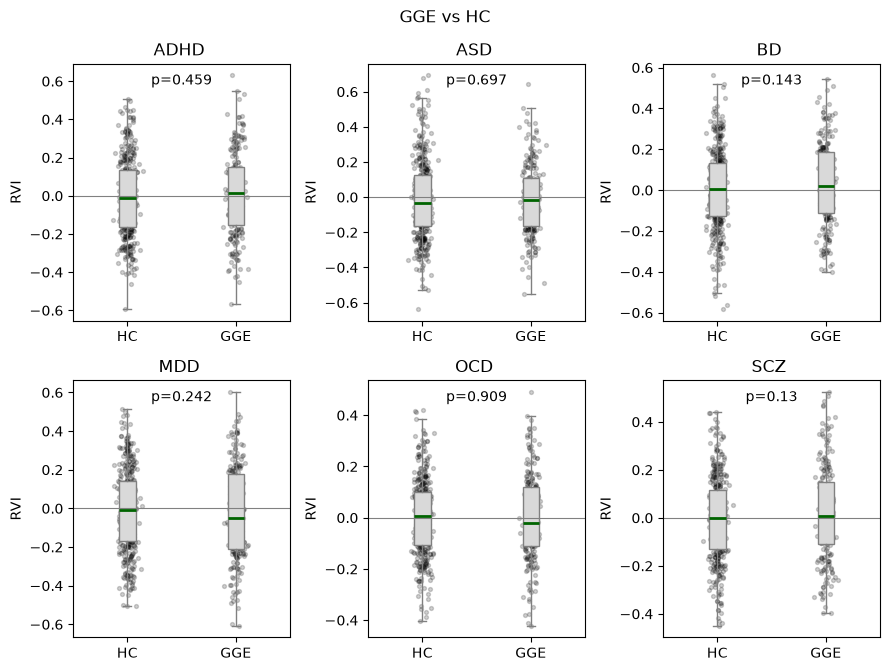

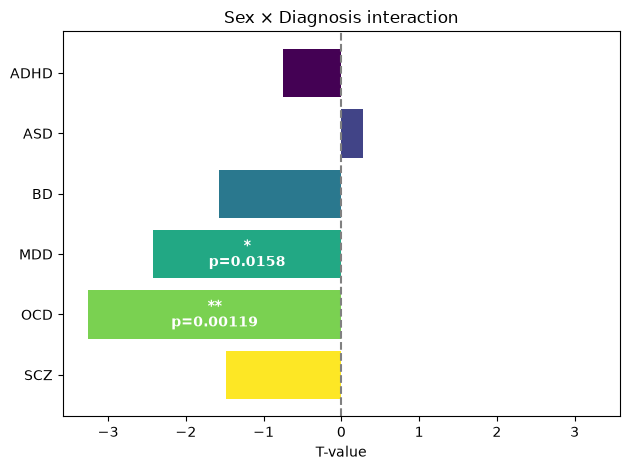

In [8]:
## 9. RVI visualization
order = list(RVI_gge)
star = lambda p: "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else ""

# GGE vs HC
fig, axs = plt.subplots(2, 3, figsize=(9, 6.8))

for ax, d in zip(axs.flat, order):
    v = [rvi_gge.loc[rvi_gge.Dx == x, d] for x in (0, 1)]
    p = case_control_gge.loc[case_control_gge.Disorder.eq(d), "P"].iloc[0]

    ax.boxplot(v, tick_labels=["HC", "GGE"], showfliers=False, patch_artist=True,
               medianprops={"color":"darkgreen","linewidth":2},
               boxprops={"facecolor":"#d9d9d9","edgecolor":"gray"},
               whiskerprops={"color":"gray"}, capprops={"color":"gray"})

    for i, y in enumerate(v, 1):
        ax.scatter(np.random.normal(i, .04, len(y)), y, s=8, alpha=.18, color="black")

    ax.axhline(0, color="gray", lw=.8)
    ax.set_title(f"{d} {star(p)}")
    ax.text(.5, .96, f"p={p:.3g}", transform=ax.transAxes, ha="center", va="top")
    ax.set_ylabel("RVI")

fig.suptitle("GGE vs HC")
plt.tight_layout()
plt.savefig("GGE_vs_HC.png", dpi=300, bbox_inches="tight")
plt.show()


def barfig(df, title, name):
    d = df.set_index("Disorder").loc[order].reset_index()
    bars = plt.barh(d["Disorder"], d["T"],
                    color=plt.cm.viridis(np.linspace(0, 1, len(d))))

    plt.axvline(0, color="gray", ls="--")
    lim = d["T"].abs().max() * 1.1
    plt.xlim(-lim, lim)

    for b, p in zip(bars, d["P"]):
        if p < .05:
            plt.text(b.get_width()/2, b.get_y()+b.get_height()/2,
                     f"{star(p)}\np={p:.3g}",
                     ha="center", va="center",
                     color="white", fontweight="bold")

    plt.gca().invert_yaxis()
    plt.xlabel("T-value")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(name + ".png", dpi=300, bbox_inches="tight")
    plt.show()

barfig(interaction_gge, "Sex × Diagnosis interaction", "GGE_Sex_Dx")